# Scientific-agent benchmark: model comparison

The main figure compares model configurations on **Mean Persona Performance, fact recovery, and actor self-repetition**, with 95% bootstrap confidence intervals. Bars average four injected personas (155 / 001 / 003 / 046) equally; persona-off is a point reference for performance. These complementary metrics do not form a validated composite adaptation score.

The final figure uses **each model’s own available eligible questions**, without intersecting question sets across models. Within each model and metric, the existing rule still requires observations for all five settings. Astra / Haiku coverage is **101 / 200** questions for performance, **20 / 20** for fact recovery, and **79 / 137** for repetition. The figure and supporting table use the same estimates and confidence intervals.

Historical evaluator differences, availability conditioning and unequal repeats remain. This is a descriptive comparison of the available GPT-6 Astra (low) and Claude Haiku 4.5 configurations, not a controlled actor-only ranking. No incomplete Sol campaign is included.


In [1]:
from pathlib import Path
import sys,json
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
BASE=ROOT/'Experiment/02_performance_and_fields'
sys.path.insert(0,str(BASE/'code'))
import model_scorecard
# Offline only. True rereads stored original traces/API usage; no model inference.
REEXTRACT=False
scorecard=model_scorecard.build(model_scorecard.extract() if REEXTRACT else None)


| Actor model | Persona-off performance | Mean Persona Performance | Fact recovery (%) | Self-repetition (%) |
|---|---|---|---|---|
| GPT-6 Astra (low) | 47.54 [39.11, 55.46] | 48.82 [40.46, 56.67] | 88.86 [76.96, 97.68] | 12.69 [11.65, 13.73] |
| Claude Haiku 4.5 | 34.60 [29.16, 40.27] | 33.82 [28.45, 38.96] | 87.87 [76.33, 97.23] | 21.15 [19.48, 22.83] |

Estimate [pointwise 95% CI].

Haiku: 200 questions, 40 per benchmark, one trial per setting; 136 model non-submissions remain zero-score outcomes. CIs are recomputed using the same 20,000-draw, benchmark-stratified study-cluster bootstrap as the Astra row, rather than copying the merged report’s question-bootstrap intervals. Fact recovery uses the saved recovered-fact share before intent gating; repetition uses shared actor messages with the same exploratory six-word/three-position matcher as Astra. Actor output is recorded completion tokens divided by 1,000. Tool use counts execute_command/inspect_repository/execute_check actions,

## Metric definitions and aggregation

1. **Mean Persona Performance:** native 0–100 score, averaged equally over four injected settings and five source benchmarks.
2. **Fact recovery:** percentage of required withheld facts recovered across all eligible SciConv disambiguation runs; no success/failure conditioning.
3. **Actor self-repetition:** ≥3 matching aligned positions in a six-word window found in an earlier actor message. At least two ≥9-word actor messages; average later-message proportions. This is the exploratory definition selected in Experiment 09.
4. **Actor output (k tokens/episode):** persona-mean episode-total completion tokens divided by 1,000. Includes reasoning, tool-call generation and final replies; excludes simulator and judge usage. This is a unit conversion, not baseline normalization.
5. **Tool calls / episode:** absolute persona-mean execution/inspection action count across four applicable sources. Handoffs are excluded; SciConv is not treated as zero.

For each metric, retain questions observed in **all five settings**, average available trials within question, then questions within source, then sources equally. Average injected personas equally. This prevents the more-repeated personas from dominating but does not eliminate missingness or unequal-repeat uncertainty.

Resample whole studies within each source, retaining all settings together (20,000 fixed-seed draws). Report percentile 95% CIs; use the same aggregation in every draw. Token estimates and CI endpoints are divided by 1,000. Baseline-relative resource ratios are supplementary, not the main table metrics. These are pointwise, descriptive intervals conditional on the saved rollouts. Repetition and resource counts have no unconditional better direction.

In [2]:
from analysis_utils import markdown_table
coverage=[]
for metric,p in scorecard['panels'].items():
    coverage.append([metric,p['questions'],', '.join(f'{s}: {n}' for s,n in p['source_questions'].items()),' / '.join(str(p['episodes_by_setting'][a]) for a in scorecard['arms'])])
display(Markdown(markdown_table(['Metric','Common questions','Questions by benchmark','Episodes: off / 155 / 001 / 003 / 046'],coverage)))
print('Historical evaluator versions:')
display(scorecard['evaluator_versions'])

display(Markdown('### Supporting resource counts and persona-off comparisons'))
display(Markdown((model_scorecard.OUT/'resource_use_raw.md').read_text()))

for added in scorecard.get("additional_models", []):
    display(Markdown("### " + added['model'] + " — one trial per setting"))
    display(Markdown(markdown_table(['Metric','Common questions','Questions by benchmark'],
        [[m,p['questions'],str(p['source_questions'])] for m,p in added['panels'].items()])))


| Metric | Common questions | Questions by benchmark | Episodes: off / 155 / 001 / 003 / 046 |
|---|---|---|---|
| performance | 101 | asibench: 7, bixbench: 27, discoverybench: 21, expbench: 6, sciconvbench: 40 | 300 / 296 / 295 / 101 / 101 |
| fact_recovery | 20 | sciconvbench: 20 | 60 / 60 / 60 / 20 / 20 |
| self_repetition | 79 | asibench: 6, bixbench: 27, discoverybench: 21, expbench: 6, sciconvbench: 19 | 233 / 230 / 227 / 79 / 79 |
| actor_output_tokens | 101 | asibench: 7, bixbench: 27, discoverybench: 21, expbench: 6, sciconvbench: 40 | 300 / 296 / 295 / 101 / 101 |
| tool_calls | 61 | asibench: 7, bixbench: 27, discoverybench: 21, expbench: 6 | 180 / 176 / 175 / 61 / 61 |

Historical evaluator versions:


{'asibench': {'asi-b3-collaborative-b2-v1+asi-configured-judge-v1': 244,
  'unknown': 2,
  'asi-b3-collaborative-b2-v1': 83},
 'bixbench': {'bixbench-1.5-native-openended-49311180-psb-0.1': 312,
  'unknown': 106},
 'discoverybench': {'discoverybench-native-prompts-settings-strict-errors-v1+openrouter-provider-defaults-v1': 395,
  'unknown': 1},
 'expbench': {'unknown': 375},
 'sciconvbench': {'sciconv-native-clarification-persona-v1+luna-judge': 440}}

### Supporting resource counts and persona-off comparisons

| Metric | Persona-off mean / episode | Persona mean / episode | Ratio to off | Change from off (%) |
|---|---|---|---|---|
| actor_output_tokens | 4,700.62 | 5,320.35 | 1.132× | +13.18 |
| tool_calls | 5.05 | 5.06 | 1.002× | +0.19 |


### Claude Haiku 4.5 — one trial per setting

| Metric | Common questions | Questions by benchmark |
|---|---|---|
| performance | 200 | {'asibench': 40, 'bixbench': 40, 'discoverybench': 40, 'expbench': 40, 'sciconvbench': 40} |
| fact_recovery | 20 | {'sciconvbench': 20} |
| self_repetition | 137 | {'asibench': 39, 'bixbench': 5, 'discoverybench': 34, 'expbench': 39, 'sciconvbench': 20} |
| actor_output_tokens | 200 | {'asibench': 40, 'bixbench': 40, 'discoverybench': 40, 'expbench': 40, 'sciconvbench': 40} |
| tool_calls | 160 | {'asibench': 40, 'bixbench': 40, 'discoverybench': 40, 'expbench': 40} |

## Supporting analyses and reproducibility

Benchmark- and super-family-level comparisons are secondary analyses, retained in [the previous executed notebook](supporting/performance_analysis_before_scorecard.ipynb). Its saved outputs are preserved; some standalone figure paths were cleared in the earlier cleanup. Historical data remain under `data/all_available`, `data/pairwise_selected`, and `data/test_sensitivity`.

[Metric definitions, limits and caption](MODEL_SCORECARD.md) · [extraction and aggregation code](code/model_scorecard.py) · [per-episode metrics](data/model_scorecard/episodes.csv) · [coverage](data/model_scorecard/coverage.csv) · [input hashes](data/model_scorecard/provenance.json).

To reproduce: run `code/model_scorecard.py --extract` from this repository's Python environment, then rerun this notebook. `REEXTRACT=False` uses the saved derived episode table. No calls to a model or embedding service are made.

For future actor models, keep the simulator, evaluator versions, persona texts, protocol and decoding settings fixed. Freeze a shared question panel across models and report unavailable coverage before comparing ranks. The present dataset does not provide a controlled requirement-fulfillment or human-realism score.

## Supporting table — all available model-specific panels

Estimate [95% CI where available]. Haiku behavioral means and 95% CIs are collaborator-reported. The main table reports **Persona-off performance, Mean Persona Performance, Fact recovery (%), and Self-repetition (%)**. All metrics except Off average the four injected personas equally. Fact recovery covers eligible SciConv disambiguation cases; repetition uses questions eligible under all five settings. Coverage is reported above.

Actor output tokens and tool calls are retained only as [supporting resource data](data/model_scorecard/model_scorecard_all_metrics.csv), not as main-table columns.

Saved as [CSV](data/model_scorecard/model_scorecard.csv), [Markdown](data/model_scorecard/model_scorecard.md), and [LaTeX](data/model_scorecard/model_scorecard.tex).

Haiku performance covers 200 questions; Astra performance covers 101 questions eligible across its five settings. These descriptive rows have different coverage and are not a matched-panel ranking.


In [3]:
display(Markdown((model_scorecard.OUT/'model_scorecard.md').read_text()))

| Actor model | Persona-off performance | Mean Persona Performance | Fact recovery (%) | Self-repetition (%) |
|---|---|---|---|---|
| GPT-6 Astra (low) | 47.54 [39.11, 55.46] | 48.82 [40.46, 56.67] | 88.86 [76.96, 97.68] | 12.69 [11.65, 13.73] |
| Claude Haiku 4.5 | 21.97 [16.25, 27.71] | 19.72 [15.19, 24.14] | 67.95 [61.77, 74.37] | 21.43 [17.23, 24.53] |

Estimates [95% CI where available].

Haiku actor and simulator: Claude Haiku 4.5; judge: GPT-6 Astra. Performance uses 200 questions (40 per benchmark), five settings, one trial, including 120 non-submissions; 95% intervals use the benchmark-stratified study-cluster bootstrap. Haiku fact recovery (67.95%) and self-repetition (21.43%) are collaborator-reported measurements and 95% confidence intervals supplied by the author on 2026-10-07. Their underlying metric records, exact aggregation, sample counts and CI computation method are not available locally; these estimates and intervals have not been independently reproduced. They replace the incorrectly labelled older Opus-simulator values. All non-Off columns represent the four-persona mean; performance weights benchmarks and personas equally.


## Final figure — aggregate model leaderboard preview

One bar per model for each of the three metrics, with pointwise 95% bootstrap CI whiskers. Black ticks in A mark persona-off means (their intervals are in the source CSV). Each model uses its own available eligible question set for each metric; there is no cross-model intersection. The source counts and exact per-model membership are saved. Persona-specific results remain supporting data.

**Coverage:** Astra / Haiku use 101 / 200 performance questions, 20 / 20 fact-recovery questions, and 79 / 137 repetition questions. All available cases satisfying each model’s five-setting metric eligibility rule are retained. The figure agrees with the supporting table above. Model coverage differs, so these bars are descriptive summaries rather than a paired comparison on identical questions.

[Figure methods and candidate caption](MODEL_LEADERBOARD.md) · [Plotting code](code/plot_model_leaderboard.py) · [PDF](figures/model_leaderboard/model_leaderboard.pdf) · [PNG](figures/model_leaderboard/model_leaderboard.png) · [Source data](data/model_leaderboard/source_data.csv) · [Coverage](data/model_leaderboard/coverage.csv)


**Historical figure:** the Haiku series below comes from the earlier Opus-simulator campaign. The table above now uses Haiku–Haiku performance and collaborator-reported behavioral means; this historical figure has not been updated.


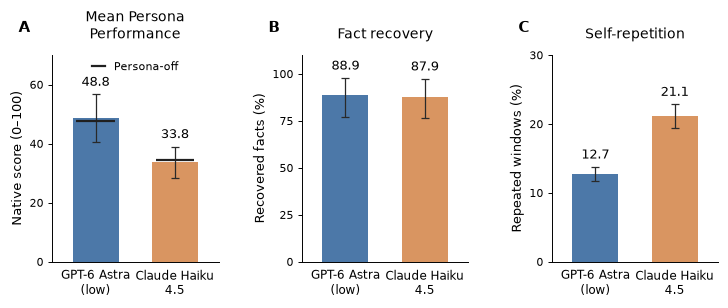

In [4]:
%matplotlib inline
import importlib
import matplotlib.pyplot as plt
import plot_model_leaderboard
importlib.reload(plot_model_leaderboard)
leaderboard_figure, leaderboard = plot_model_leaderboard.draw()
display(leaderboard_figure)
plt.close(leaderboard_figure)


### Figure caption

The caption below documents the aggregation, uncertainty, question counts and limitations for reuse in the paper.


In [5]:
caption = (BASE/'MODEL_LEADERBOARD.md').read_text().split('## Candidate caption\n',1)[1].split('## Reproduction and outputs',1)[0].strip()
display(Markdown(caption))


**Model comparison across simulator-persona conditions.** Bars show model-level means across four injected personas (155, 001, 003, 046), with pointwise 95% percentile confidence intervals from 20,000 study-cluster bootstrap samples stratified by source benchmark (seed 20261004). Each model uses its own available metric-specific question set, requiring observations for all five settings within that model; cases are not intersected across models. Available trials are averaged within question and setting, questions within source, then applicable sources and injected personas equally. All settings and observed trials of a sampled study remain together within each model's bootstrap. **A**, native performance on 101 Astra questions (ASI/Bix/Discovery/EXP/SciConv: 7/27/21/6/40; 78 study clusters) and 200 Haiku questions (40 per source; 134 study clusters). Black ticks indicate persona-off means on the corresponding model's question set; their intervals are available in source data. **B**, mean recovered fraction of withheld facts on 20 SciConv disambiguation questions per model, without success/failure conditioning. **C**, actor self-repetition on 79 Astra questions (6/27/21/6/19; 56 study clusters) and 137 Haiku questions (39/5/34/39/20; 93 study clusters): the fraction of six-word windows with at least three aligned word matches in an earlier actor message, averaged across later eligible messages. Episodes require at least two actor messages of nine or more words. Lower repetition describes less repeated text, not necessarily higher quality. The matching threshold was selected exploratorily. Coverage differs across models and metrics and is conditioned on availability. Historical evaluator differences and unequal repeats remain; intervals condition on observed rollouts and the fixed persona set. The figure is a descriptive summary of historical model configurations, not a matched or paired model comparison, a controlled actor-only ranking, or evidence of human realism.